# Benchmark visualisations (MIDI-B image/VLM track)

This notebook turns the CSVs from `vlm/vlm_score.py` into the figures used in the
report.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

MODEL_TAG   = "qwen3-vl-2b"
RESULTS_DIR = Path("../results")
FIG_DIR     = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

overall      = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_overall.csv")
per_category = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_per_category.csv")
image_level  = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_image_level.csv")
outcomes     = pd.read_csv(RESULTS_DIR / f"{MODEL_TAG}_outcomes.csv")
manifest     = pd.read_csv(Path("../data/midi-b/images_png/manifest.csv"))

# one fixed colour per condition -- same assignment as benchmark_visualisations.ipynb,
# so a condition looks the same across both notebooks' figures
COLORS = {"zeroshot": "#2a78d6", "fewshot": "#eb6834", "presidio": "#1baf7a", "fewshot_think": "#eda100"}
NAMES  = {"zeroshot": "Qwen3-VL zero-shot", "fewshot": "Qwen3-VL few-shot",
          "presidio": "ocrmac + Presidio (baseline)", "fewshot_think": "Qwen3-VL few-shot + thinking"}
ORDER  = [c for c in COLORS if c in set(overall.condition)]
print("conditions:", ORDER)

SURFACE, TEXT, TEXT2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT2, "text.color": TEXT,
    "xtick.color": TEXT2, "ytick.color": TEXT2, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})

# A bar at height 0 is invisible, which looks like missing data rather than "we
# measured this, and it was zero". So exact zeros get a thin visible sliver instead
# -- the printed label still shows the true value.
FLOOR = 0.015

def floor_heights(values):
    return [FLOOR if v == 0 else v for v in values]

def grouped_bars(ax, frame, x_col, x_order, value_col, x_labels=None, horizontal=False, order=None, colors=None, names=None):
    """one bar per series (ORDER by default) and x value; values are written on the bars"""
    order = order or ORDER
    colors = colors or COLORS
    names = names or NAMES
    n = len(order)
    width = 0.8 / n
    for k, c in enumerate(order):
        sub = frame[frame.condition == c].set_index(x_col).reindex(x_order)
        true_vals = sub[value_col].tolist()
        pos = [i + (k - (n - 1) / 2) * width for i in range(len(x_order))]
        draw = ax.barh if horizontal else ax.bar
        bars = draw(pos, floor_heights(true_vals), width, color=colors[c], label=names[c],
                    edgecolor=SURFACE, linewidth=1.5)
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in true_vals], fontsize=7, color=TEXT2, padding=2)
    ticks = x_labels or x_order
    if horizontal:
        ax.set_yticks(range(len(x_order)), ticks)
        ax.grid(axis="y", visible=False)
        ax.set_xlim(0, 1.1)
    else:
        ax.set_xticks(range(len(x_order)), ticks)
        ax.grid(axis="x", visible=False)
        ax.set_ylim(0, 1.1)

def save(fig, name):
    path = FIG_DIR / f"{MODEL_TAG}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path)

conditions: ['zeroshot', 'fewshot', 'presidio']


## 1. Overall precision, recall and F1

These are micro-averaged scores across every predicted span, in two matching modes:

- **overlap** — the prediction shares characters with the gold span and agrees on the label
- **any** — they just need to overlap; the label doesn't have to match. This is the more forgiving "would this PHI have been caught at all?" view

We also tried a stricter mode that requires exact boundary matches, but MIDI-B
bundles several PHI types — name, sex, date, birth date — into a single annotation
box, so no classifier's shorter spans ever line up with it exactly. That mode scored
0 everywhere and wasn't telling us anything, so it's left out here.

saved ../results/figures/qwen3-vl-2b_overall.png


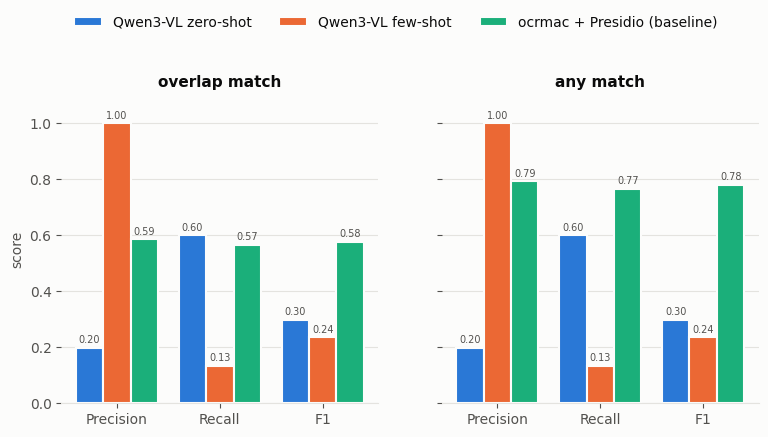

In [2]:
metrics = ["precision", "recall", "f1"]
long = overall.melt(id_vars=["condition", "mode"], value_vars=metrics, var_name="metric")

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, mode in zip(axes, ["overlap", "any"]):
    grouped_bars(ax, long[long["mode"] == mode], "metric", metrics, "value", ["Precision", "Recall", "F1"])
    ax.set_title(f"{mode} match")
axes[0].set_ylabel("score")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.3), ncol=len(ORDER))
save(fig, "overall")
plt.show()

## 2. Results per shared PHI category

Here we break the overlap-mode scores down by category — NAME and DATE only, since
those are the only ones that actually show up as burned-in PHI in this set of
images. LOCATION, CONTACT and ID never appear, so there's nothing real to measure
recall against for them; any predictions there would just be false alarms, not a
meaningful score.

saved ../results/figures/qwen3-vl-2b_per_category.png


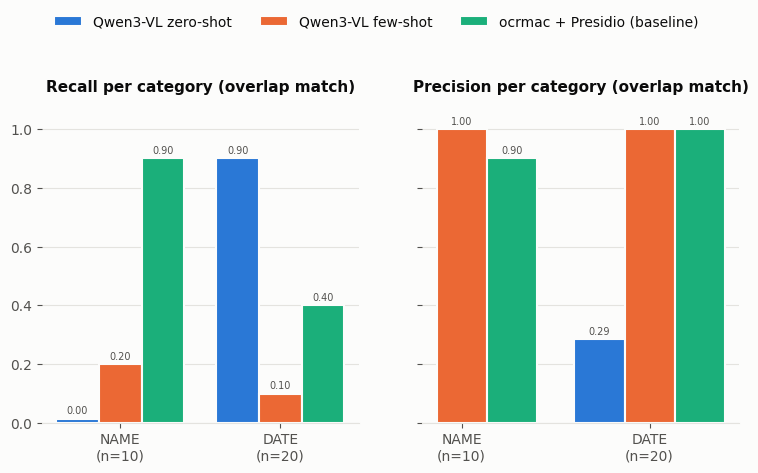

In [3]:
MODE = "overlap"
labels = ["NAME", "DATE"]
cat = per_category[(per_category["mode"] == MODE) & (per_category.label.isin(labels))]
n_gold = cat.drop_duplicates("label").set_index("label")["n_gold"]
ticks = [f"{l}\n(n={n_gold[l]})" for l in labels]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
for ax, metric in zip(axes, ["recall", "precision"]):
    grouped_bars(ax, cat, "label", labels, metric, ticks)
    ax.set_title(f"{metric.capitalize()} per category ({MODE} match)")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.3), ncol=len(ORDER))
save(fig, "per_category")
plt.show()

## 3. Recall per modality

How well does each condition do on X-rays (CR), digital X-rays (DX) and
mammograms (MG)? We use `any` mode here — would the PHI have been caught at all,
regardless of label. Only 10 images actually contain PHI, split unevenly across the
three modalities, so treat this as a rough picture rather than a precise estimate.

saved ../results/figures/qwen3-vl-2b_per_modality.png


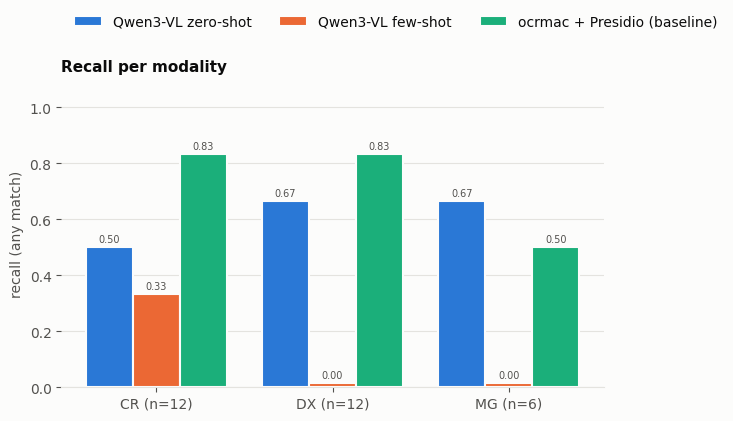

In [4]:
merged = outcomes.merge(manifest[["sop_instance_uid", "modality"]],
                         left_on="id", right_on="sop_instance_uid", how="left")
gold_m = merged[merged.side == "gold"]

per_modality = []
for c in ORDER:
    for mod in sorted(gold_m.modality.unique()):
        sub = gold_m[(gold_m.condition == c) & (gold_m.modality == mod)]
        n = len(sub)
        recall_any = sub.matched_any.sum() / n if n else float("nan")
        per_modality.append({"condition": c, "modality": mod, "n": n, "recall_any": recall_any})
per_modality = pd.DataFrame(per_modality)

mods = sorted(gold_m.modality.unique())
n_by_mod = gold_m[gold_m.condition == ORDER[0]].groupby("modality").size()  # same for every condition
ticks = [f"{m} (n={n_by_mod.get(m, 0)})" for m in mods]

fig, ax = plt.subplots(figsize=(7, 4))
grouped_bars(ax, per_modality, "modality", mods, "recall_any", ticks)
ax.set_ylabel("recall (any match)")
ax.set_title("Recall per modality", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.25), ncol=len(ORDER))
save(fig, "per_modality")
plt.show()

## 4. Image-level privacy metrics

Two numbers that matter more in practice than per-span precision and recall:

- **Leak-free rate** — of the images that actually contain PHI, how many get it
  *all* caught? Higher is better.
- **False alarm rate** — of the images with no PHI at all, how many still get
  flagged? Lower is better.

saved ../results/figures/qwen3-vl-2b_image_level.png


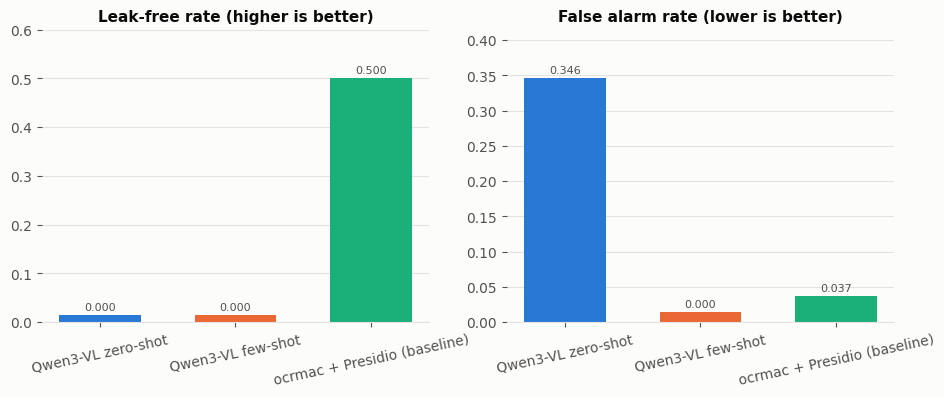

In [5]:
q = image_level.set_index("condition").reindex(ORDER)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["leak_free_rate", "false_alarm_rate"],
                          ["Leak-free rate (higher is better)", "False alarm rate (lower is better)"]):
    true_vals = q[col].tolist()
    bars = ax.bar([NAMES[c] for c in ORDER], floor_heights(true_vals), color=[COLORS[c] for c in ORDER], width=0.6)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in true_vals], fontsize=8, color=TEXT2, padding=2)
    ax.set_ylim(0, max(1e-9, q[col].max()) * 1.2)
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=12)
save(fig, "image_level")
plt.show()

## 5. Text track vs. image track

This is the real question behind the project: does PHI get missed more often when
it's buried in pixels instead of written out as text? We compare the two tracks on
NAME and DATE, the only categories with real examples on both sides, using the same
matching code and taxonomy for both — so any gap we see is about the modality, not
about how we're scoring it.

One thing worth keeping in mind: the two tracks aren't running the same model end to
end. The text track hands Qwen3-0.6B the raw text and asks it to find PHI directly.
The image track first has Qwen3-VL read the image into a transcript (that's all it
does — no PHI judgement), and then hands that transcript to the same Qwen3-0.6B
prompt the text track uses. So "zero-shot" and "few-shot" below refer to that shared
classification step, not to one model doing the whole job in both cases — the
legend spells out each track's actual pipeline.

saved ../results/figures/qwen3-vl-2b_cross_modality.png


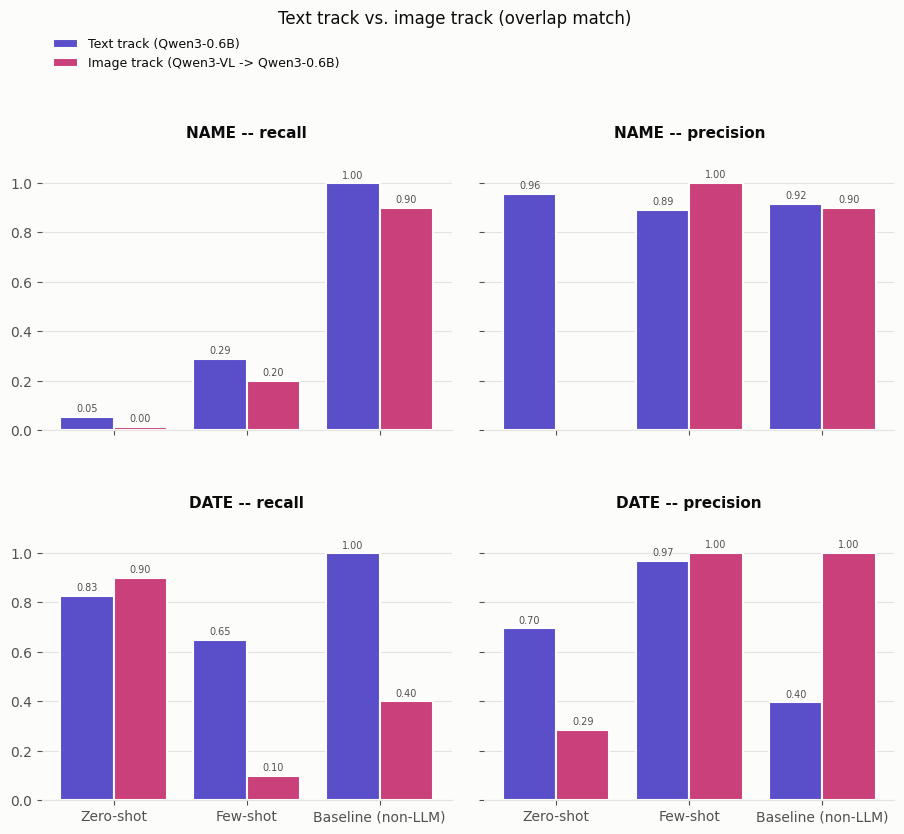

In [6]:
text_cat = pd.read_csv(RESULTS_DIR / "qwen3-0.6b_per_category.csv")
text_cat = text_cat[(text_cat["mode"] == "overlap") & (text_cat.label.isin(["NAME", "DATE"]))].copy()
text_cat["track"] = "Text track (Qwen3-0.6B)"

image_cat = per_category[(per_category["mode"] == "overlap") & (per_category.label.isin(["NAME", "DATE"]))].copy()
image_cat["track"] = "Image track (Qwen3-VL -> Qwen3-0.6B)"

combined = pd.concat([text_cat, image_cat], ignore_index=True)
combined = combined[combined.condition.isin(ORDER)]

TRACK_COLORS = {"Text track (Qwen3-0.6B)": "#5b4fc9",
                 "Image track (Qwen3-VL -> Qwen3-0.6B)": "#c9407a"}
TRACK_ORDER = list(TRACK_COLORS)
COND_LABELS = {"zeroshot": "Zero-shot", "fewshot": "Few-shot", "presidio": "Baseline (non-LLM)"}

def track_bars(ax, frame, metric, show_xticks):
    n = len(TRACK_ORDER)
    width = 0.8 / n
    for k, track in enumerate(TRACK_ORDER):
        sub = frame[frame.track == track].set_index("condition").reindex(ORDER)
        true_vals = sub[metric].tolist()
        pos = [i + (k - (n - 1) / 2) * width for i in range(len(ORDER))]
        bars = ax.bar(pos, floor_heights(true_vals), width, color=TRACK_COLORS[track], label=track,
                       edgecolor=SURFACE, linewidth=1.5)
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in true_vals], fontsize=7, color=TEXT2, padding=2)
    ax.set_xticks(range(len(ORDER)))
    if show_xticks:
        ax.set_xticklabels([COND_LABELS[c] for c in ORDER])
    else:
        ax.set_xticklabels([])
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 1.15)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), sharey=True, sharex="col")
fig.subplots_adjust(hspace=0.3, wspace=0.08)
for row, label in enumerate(["NAME", "DATE"]):
    for col, metric in enumerate(["recall", "precision"]):
        ax = axes[row, col]
        track_bars(ax, combined[combined.label == label], metric, show_xticks=(row == 1))
        ax.set_title(f"{label} -- {metric}")
axes[0, 0].legend(loc="upper left", bbox_to_anchor=(0, 1.42), ncol=1, fontsize=9)
fig.suptitle("Text track vs. image track (overlap match)", y=1.04)
save(fig, "cross_modality")
plt.show()

If a condition does well on text but poorly on the matching
image bar (or the other way around), that's a genuine modality-specific blind spot and not just noise from comparing different
datasets or scoring methods, since those are controlled for here.